In [2]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.cluster import KMeans


In [3]:
#read data set and save to waves
waves= pd.read_csv(
    '/Users/gabrielagarcia/Desktop/Fall 2026/Geol 415/HW8/Waves_2023.txt',
    sep=r'\s+')
#remove the listed columns
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
#filter out bad data
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

#drop listed columns
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)
print(wavesML.head())

   WVHT    DPD   APD  MWD  WTMP
0  1.12  12.50  7.69  269  15.3
1  1.16  11.76  7.34  272  15.3
2  1.20  12.50  7.08  268  15.3
3  1.25  10.53  7.33  268  15.4
4  1.27  10.53  7.57  268  15.5


In [4]:
#Standardize data
#create standardization function
def z_score(df):
    # subtract the column mean, then divide by the column standard deviation
    return (df - df.mean()) / df.std()


In [5]:
#standardize wavesML data
waves_z = z_score(wavesML) # 
waves_z.head()

,WVHT,DPD,APD,MWD,WTMP
0,0.166100,0.104602,0.499276,0.753178,-0.738984
1,0.242054,-0.097312,0.310355,0.818029,-0.738984
2,0.318007,0.104602,0.170014,0.731562,-0.738984
3,0.412949,-0.432925,0.304957,0.731562,-0.699994
4,0.450926,-0.432925,0.434503,0.731562,-0.661003


In [6]:
from sklearn.decomposition import PCA

In [7]:
#set number of components equal to dimensionality of data
pca = PCA(n_components=5)
waves_scaled = pca.fit_transform(waves_z)

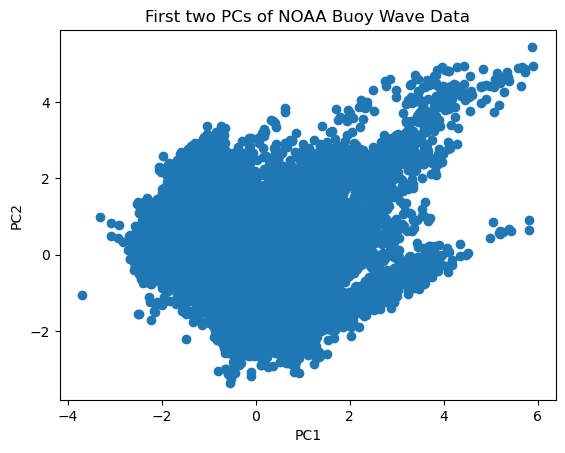

In [8]:
#plot PC1 vs PC2
plt.subplots()
plt.scatter(waves_scaled[:, 0], waves_scaled[:, 1])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('First two PCs of NOAA Buoy Wave Data')
plt.show()

Text(0.5, 1.0, 'Proportion Variance explained per PC')

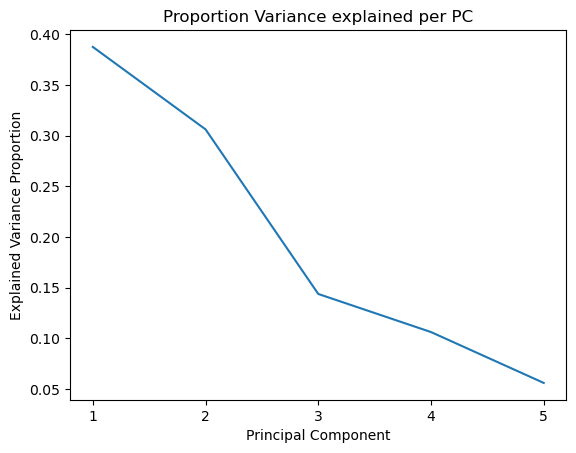

In [9]:
#Generate elbow plot
# create variable for variance explained by each PC 
variance_props = pca.explained_variance_ratio_
#create axis range that doesn't start at 0
xdata = range(1,len(variance_props)+1)
#plot PCs vs their variance proportion
plt.plot(xdata, variance_props)
plt.xticks(xdata)
plt.ylabel('Explained Variance Proportion')
plt.xlabel('Principal Component')
plt.title('Proportion Variance explained per PC')

In [10]:
#2)Three components are needed to capture most of the data (approximately 85%).

In [11]:
num_pcs = 3

# for each PC, let's look at the top 10 vector components (loadings) that contribute to that PC.
# pca.components_[pc] holds the loadings for that PC; we rank by absolute value (sign doesn't matter for importance).
for pc in range(num_pcs):
    ranked_loadings = np.argsort(np.abs(pca.components_[pc]))[::-1]
    print(f"Ranked loadings for PC{pc+1}:")
    print(waves_z.columns[ranked_loadings])
    print("\n")

Ranked loadings for PC1:
Index(['MWD', 'WVHT', 'WTMP', 'APD', 'DPD'], dtype='object')


Ranked loadings for PC2:
Index(['DPD', 'APD', 'MWD', 'WVHT', 'WTMP'], dtype='object')


Ranked loadings for PC3:
Index(['WTMP', 'WVHT', 'DPD', 'APD', 'MWD'], dtype='object')




In [12]:
#3) Each PC had a different ranking of variables from most to least contribution.  For PC1, MWD and WVHT contributed the most.  
#For PC2 it was DPD and APD.  For PC3 it was WTMP and WVHT.  Only PC1 and PC3 had one variable in common and it was WVHT.
#4) A good PCA explains most of the variance with a few components.  Bad performance would tell me that my data does not
# have strong linear relationship and that dropping any component would be more meaningful than if I had a strong PCA and 
#was dropping components after the elbow curve number.  Limitations are that it might not fit all types of data.

In [13]:
#5) Same as plot above.

In [14]:
#new pca with three components based on proportion variance explained by PC plot
pca_2= PCA(n_components=3)
#run pca.fit_transform to get in array format
waves_scaled_2=pca_2.fit_transform(waves_z)

In [16]:
#run pca result through k-means
wcluster=[]
# create 10 clusters and add to wcluster. k-means++ places cluster centers far apart from each other
for i in range (1,11):
    kmeans_pca=KMeans(n_clusters=i, init= 'k-means++', random_state=42)
    kmeans_pca.fit(waves_scaled_2)
    wcluster.append(kmeans_pca.inertia_)

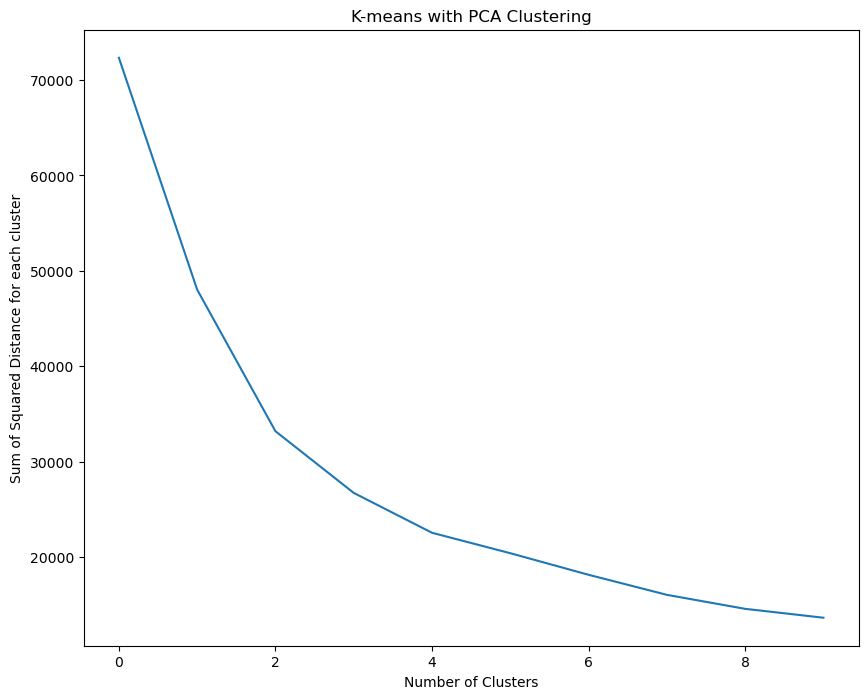

In [17]:
plt.figure(figsize=(10,8))
plt.xlabel('Number of Clusters')
plt.plot(wcluster)
plt.ylabel('Sum of Squared Distance for each cluster')
plt.title('K-means with PCA Clustering')
plt.show()

In [ ]:
#7. 4 clusters is the right choice.  Elbow curve smoothens out after four.

In [27]:
#run kmeans with four clusters
kmeans_pca_4= KMeans(n_clusters=4, init='k-means++', random_state=42)
clusters_4= kmeans_pca_4.fit_transform(waves_scaled_2)
#get the cluster centers
cluster_labels=np.argmin(clusters_4,axis=1)
centers=kmeans_pca_4.cluster_centers_


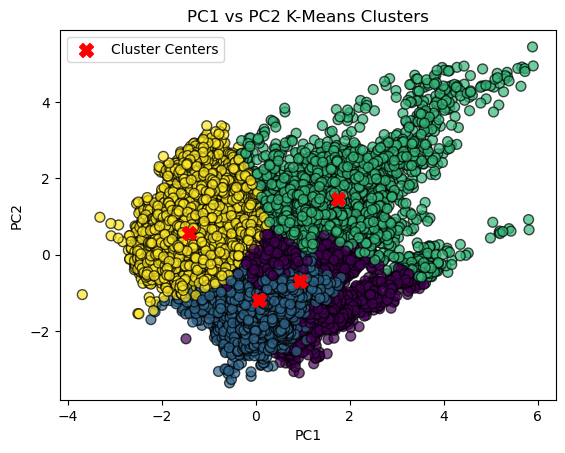

In [36]:
#plot the cluster centers and pca
#c=cluster_labels assigns color to each point corresponding to its cluster
plt.scatter(
    waves_scaled_2[:,0],
    waves_scaled_2[:,1], c=cluster_labels,alpha=0.7, edgecolors='k', s=50)
plt.scatter(centers[:,0], centers[:,1], c='red', marker='X', s=100, label='Cluster Centers')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PC1 vs PC2 K-Means Clusters')
plt.legend()
plt.show()


In [ ]:
#9.  This clustering does not make sense with what I can see for one of the purple cluster.  The purple cluster 
#seems to be broken up by the blue one and its center overlaps with the blue data points.